# Giai đoạn 4: Mô hình dự báo phụ tải ngày tới

Notebook đọc kết quả backtest do `train.py` tạo ra (`data/backtest*.csv`, `models/params.json`) và phân tích chúng. Phương pháp và kết luận: `docs/Model.md`.

Chạy lại toàn bộ:
```
python train.py
jupyter nbconvert --to notebook --execute --inplace notebooks/02_modeling.ipynb
```

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import features as F
import train as T

FIG = ROOT / "reports" / "figures"
pd.set_option("display.width", 160)
C = {"s1": "#2a78d6", "s2": "#eb6834", "s3": "#1baf7a", "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#898781",
     "grid": "#e1e0d9", "axis": "#c3c2b7", "surface": "#fcfcfb", "band": "#cde2fb"}
plt.rcParams.update({
    "font.family": "Segoe UI", "font.size": 10,
    "figure.facecolor": C["surface"], "axes.facecolor": C["surface"], "savefig.facecolor": C["surface"],
    "axes.edgecolor": C["axis"], "axes.labelcolor": C["ink2"], "axes.titlecolor": C["ink"],
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": C["muted"], "ytick.color": C["muted"], "text.color": C["ink"],
    "lines.linewidth": 1.5, "legend.frameon": False,
})

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

bt = pd.read_csv(ROOT / "data" / "backtest.csv", parse_dates=["date"]).set_index("date")
met = pd.read_csv(ROOT / "data" / "backtest_metrics.csv")
dm = pd.read_csv(ROOT / "data" / "backtest_dm.csv")
params = json.loads((ROOT / "models" / "params.json").read_text(encoding="utf-8"))
FINAL = {t: params[t]["final"] for t in F.TARGETS}
NAMES = {"pmax_mw": "Pmax", "energy_mkwh": "Sản lượng"}
print("Mô hình cuối (chọn theo tập kiểm định):", FINAL)

Mô hình cuối (chọn theo tập kiểm định): {'pmax_mw': 'ensemble', 'energy_mkwh': 'ridge'}


## 1. Tham số được chọn trên tập kiểm định (11/11/2024 → 10/11/2025)

In [2]:
rows = []
for t in F.TARGETS:
    p = params[t]
    rows.append({"biến": NAMES[t], "Ridge alpha": p["ridge_alpha"], **{f"LGB {k}": v for k, v in p["lgb"].items()},
                 **{f"MAPE kiểm định: {k}": round(v, 2) for k, v in p["valid_mape"].items()}, "mô hình cuối": p["final"]})
display(pd.DataFrame(rows).set_index("biến").T)

biến,Pmax,Sản lượng
Ridge alpha,10,1
LGB objective,l1,l2
LGB num_leaves,15,15
LGB min_child_samples,10,10
LGB n_estimators,600,300
MAPE kiểm định: clean_base,4.81,5.83
MAPE kiểm định: ridge,2.34,2.2
MAPE kiểm định: lightgbm,2.37,2.65
MAPE kiểm định: ensemble,2.25,2.32
mô hình cuối,ensemble,ridge


## 2. Kết quả trên tập test (11/11/2025 → 10/11/2026)

Mọi mô hình được tính trên **cùng một tập ngày** (ngày có số liệu thực tế và có đủ dự báo của mọi mô hình).

In [3]:
order = ["lag2", "lag7", "mean_lag7_28", "clean_base", "ridge", "lightgbm", "ensemble"]
segs = ["tất cả", "ngày thường", "lễ/Tết", "nắng nóng (top 10% Tmax)"]
for t in F.TARGETS:
    m = met[met.target == t]
    tab = m.pivot_table(index="model", columns="segment", values="MAPE").reindex(order)[segs].round(2)
    tab["MAE (tất cả)"] = m[m.segment == "tất cả"].set_index("model").reindex(order)["MAE"].round(0)
    tab["n (tất cả)"] = m[m.segment == "tất cả"].set_index("model").reindex(order)["n"]
    print(f"MAPE (%) — {NAMES[t]} (đơn vị MAE: {'MW' if t == 'pmax_mw' else 'triệu kWh'})")
    display(tab)

MAPE (%) — Pmax (đơn vị MAE: MW)


segment,tất cả,ngày thường,lễ/Tết,nắng nóng (top 10% Tmax),MAE (tất cả),n (tất cả)
model,,,,,,
lag2,7.08,6.62,13.55,6.11,3282.0,329
lag7,5.67,4.16,26.65,6.45,2560.0,329
mean_lag7_28,5.12,3.74,24.44,7.37,2270.0,329
clean_base,4.46,2.92,25.86,6.64,1934.0,329
ridge,2.21,2.01,5.14,3.33,1051.0,329
lightgbm,2.24,1.92,6.65,2.24,1038.0,329
ensemble,2.12,1.86,5.71,2.71,993.0,329


MAPE (%) — Sản lượng (đơn vị MAE: triệu kWh)


segment,tất cả,ngày thường,lễ/Tết,nắng nóng (top 10% Tmax),MAE (tất cả),n (tất cả)
model,,,,,,
lag2,6.33,5.75,14.40,5.97,59.0,329
lag7,6.34,4.75,28.54,6.60,58.0,329
mean_lag7_28,5.88,4.46,25.60,8.23,53.0,329
clean_base,5.03,3.48,26.58,7.52,44.0,329
ridge,2.10,1.92,4.63,2.47,20.0,329
lightgbm,2.19,1.93,5.82,2.19,21.0,329
ensemble,2.00,1.82,4.47,2.24,19.0,329


### Kiểm định Diebold–Mariano

So sánh sai số phần trăm tuyệt đối của từng mô hình với baseline. DM < 0 nghĩa là mô hình chính xác hơn. Hiệu chỉnh mẫu nhỏ của Harvey và cộng sự (1997), khoảng cách dự báo h = 2.

In [4]:
display(dm.round(4))

,target,model,vs,DM,p_value,n
0,pmax_mw,ridge,mean_lag7_28,-4.8854,0.0000,329
1,pmax_mw,ridge,clean_base,-3.7410,0.0002,329
2,pmax_mw,lightgbm,mean_lag7_28,-5.2986,0.0000,329
3,pmax_mw,lightgbm,clean_base,-4.0710,0.0001,329
4,pmax_mw,ensemble,mean_lag7_28,-5.3129,0.0000,329
5,pmax_mw,ensemble,clean_base,-4.1159,0.0000,329
6,energy_mkwh,ridge,mean_lag7_28,-5.6880,0.0000,329
7,energy_mkwh,ridge,clean_base,-4.4848,0.0000,329
8,energy_mkwh,lightgbm,mean_lag7_28,-5.8823,0.0000,329
9,energy_mkwh,lightgbm,clean_base,-4.6207,0.0000,329


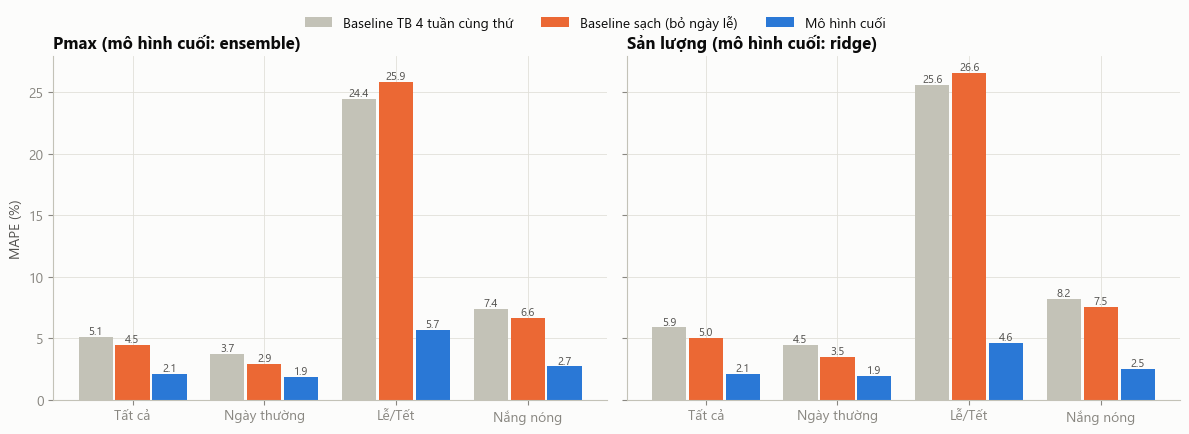

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
show = [("mean_lag7_28", "Baseline TB 4 tuần cùng thứ", C["axis"]), ("clean_base", "Baseline sạch (bỏ ngày lễ)", C["s2"]),
        ("FINAL", "Mô hình cuối", C["s1"])]
for ax, t in zip(axes, F.TARGETS):
    m = met[met.target == t].set_index(["model", "segment"])["MAPE"]
    x = np.arange(len(segs))
    w = 0.26
    for i, (k, lab, c) in enumerate(show):
        name = FINAL[t] if k == "FINAL" else k
        v = [m[(name, s)] for s in segs]
        ax.bar(x + (i - 1) * (w + 0.02), v, width=w, color=c, label=lab if t == "pmax_mw" else None)
        for xi, vi in zip(x, v):
            ax.annotate(f"{vi:.1f}", (xi + (i - 1) * (w + 0.02), vi), xytext=(0, 2), textcoords="offset points",
                        ha="center", fontsize=8, color=C["ink2"])
    ax.set_xticks(x, ["Tất cả", "Ngày thường", "Lễ/Tết", "Nắng nóng"])
    ax.set_title(f"{NAMES[t]} (mô hình cuối: {FINAL[t]})")
axes[0].set_ylabel("MAPE (%)")
fig.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.04))
fig.tight_layout()
save(fig, "08_mape_by_segment")

## 3. Dự báo so với thực tế trên tập test

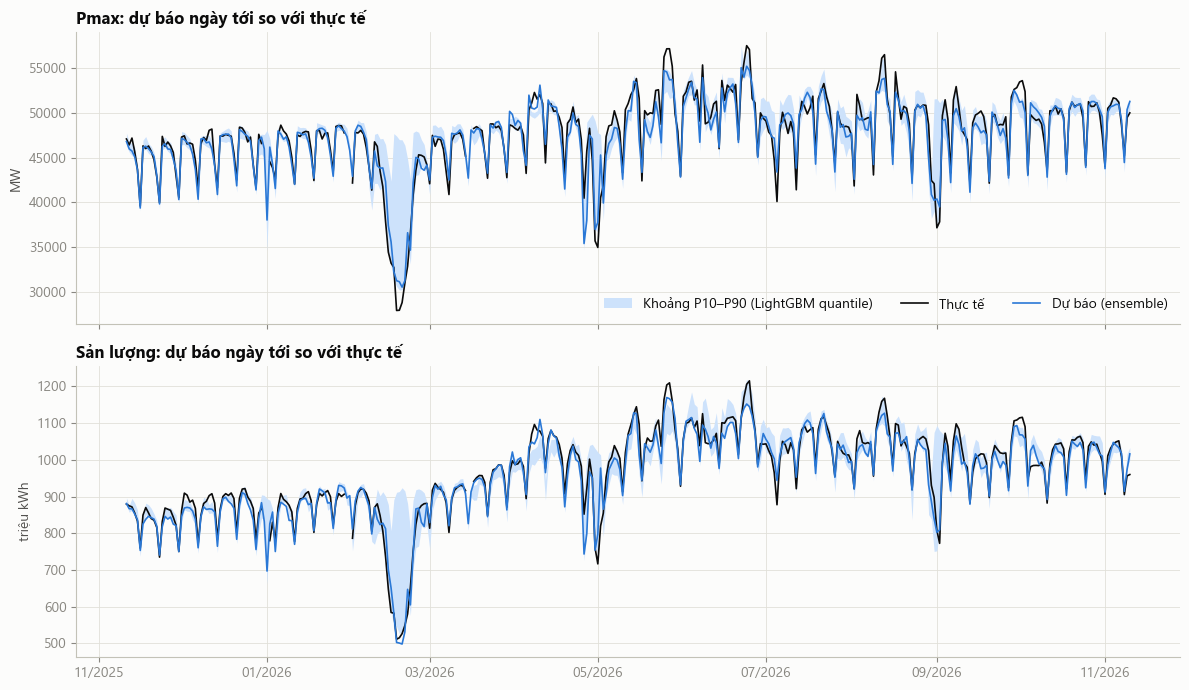

Độ phủ của khoảng dự báo:


,độ phủ thực tế P10–P90,kỳ vọng,dưới P10,trên P90,độ rộng TB (% của y)
biến,,,,,
Pmax,0.663,0.8,0.123,0.214,5.89
Sản lượng,0.641,0.8,0.114,0.245,6.76


In [6]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, t in zip(axes, F.TARGETS):
    d = bt[bt.target == t]
    ax.fill_between(d.index, d["lgb_p10"], d["lgb_p90"], color=C["band"], lw=0, label="Khoảng P10–P90 (LightGBM quantile)")
    ax.plot(d.index, d["y"], color=C["ink"], lw=1.2, label="Thực tế")
    ax.plot(d.index, d[FINAL[t]], color=C["s1"], lw=1.2, label=f"Dự báo ({FINAL[t]})")
    ax.set_title(f"{NAMES[t]}: dự báo ngày tới so với thực tế")
    ax.set_ylabel("MW" if t == "pmax_mw" else "triệu kWh")
axes[0].legend(loc="lower right", ncol=3)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
fig.tight_layout()
save(fig, "09_backtest")

rows = []
for t in F.TARGETS:
    d = bt[bt.target == t].dropna(subset=["y", "lgb_p10", "lgb_p90"])
    inside = (d["y"] >= d["lgb_p10"]) & (d["y"] <= d["lgb_p90"])
    rows.append({"biến": NAMES[t], "độ phủ thực tế P10–P90": round(inside.mean(), 3), "kỳ vọng": 0.8,
                 "dưới P10": round((d["y"] < d["lgb_p10"]).mean(), 3), "trên P90": round((d["y"] > d["lgb_p90"]).mean(), 3),
                 "độ rộng TB (% của y)": round(((d["lgb_p90"] - d["lgb_p10"]) / d["y"]).mean() * 100, 2)})
print("Độ phủ của khoảng dự báo:")
display(pd.DataFrame(rows).set_index("biến"))

### Sai số theo tháng

In [7]:
rows = {}
for t in F.TARGETS:
    d = bt[bt.target == t].dropna(subset=["y", FINAL[t], "mean_lag7_28"])
    ape = lambda c: (np.abs(d[c] - d["y"]) / d["y"] * 100)
    rows[(NAMES[t], "mô hình cuối")] = ape(FINAL[t]).resample("MS").mean()
    rows[(NAMES[t], "TB 4 tuần")] = ape("mean_lag7_28").resample("MS").mean()
mon = pd.DataFrame(rows).round(2)
mon.index = mon.index.strftime("%m/%Y")
display(mon)

Pmax              Sản lượng          
        mô hình cuối TB 4 tuần mô hình cuối TB 4 tuần
date                                                 
11/2025         0.94      1.05         1.23      1.34
12/2025         1.10      1.90         2.34      3.03
01/2026         1.21      1.68         2.21      2.93
02/2026         3.61     17.19         2.87     18.97
03/2026         1.22      9.92         0.88     12.85
04/2026         3.18      5.32         2.62      6.69
05/2026         3.79      8.26         3.21      9.51
06/2026         2.13      3.46         1.95      3.24
07/2026         2.27      5.04         1.66      4.41
08/2026         2.11      3.27         2.24      3.12
09/2026         2.33      6.08         2.15      6.28
10/2026         1.43      2.08         1.90      3.17
11/2026         1.24      1.70         1.66      2.30

## 4. Tết 2026

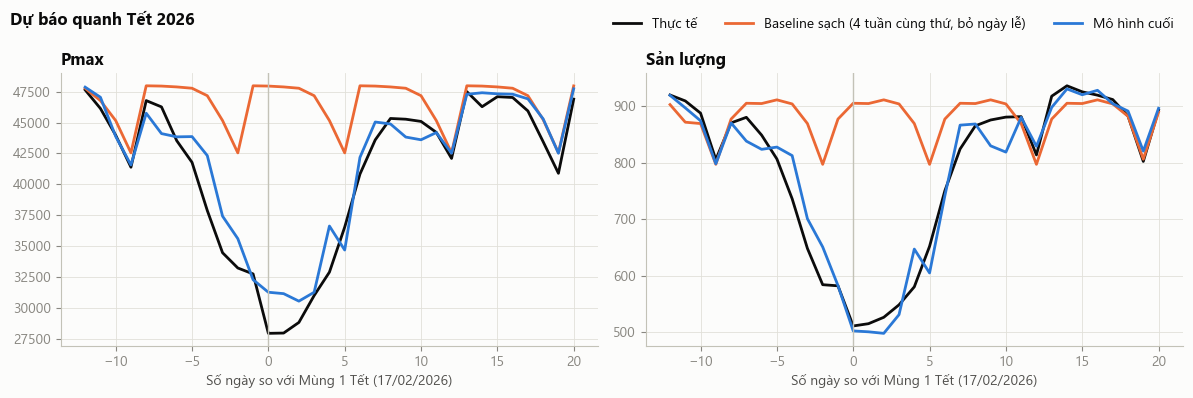

Pmax MAPE Tết (−10 → +15): {'mean_lag7_28': 20.23, 'clean_base': 20.55, 'ridge': 3.62, 'lightgbm': 5.05, 'ensemble': 4.13}
Sản lượng MAPE Tết (−10 → +15): {'mean_lag7_28': 22.84, 'clean_base': 22.48, 'ridge': 3.8, 'lightgbm': 4.17, 'ensemble': 3.24}


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for ax, t in zip(axes, F.TARGETS):
    d = bt[(bt.target == t) & bt["tet_offset"].between(-12, 20)]
    ax.plot(d["tet_offset"], d["y"], color=C["ink"], lw=2, label="Thực tế")
    ax.plot(d["tet_offset"], d["clean_base"], color=C["s2"], lw=2, label="Baseline sạch (4 tuần cùng thứ, bỏ ngày lễ)")
    ax.plot(d["tet_offset"], d[FINAL[t]], color=C["s1"], lw=2, label="Mô hình cuối")
    ax.axvline(0, color=C["axis"], lw=1)
    ax.set_title(NAMES[t])
    ax.set_xlabel("Số ngày so với Mùng 1 Tết (17/02/2026)")
fig.suptitle("Dự báo quanh Tết 2026", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper right", ncol=3, bbox_to_anchor=(0.99, 1.0))
save(fig, "10_tet_2026")
for t in F.TARGETS:
    d = bt[(bt.target == t) & bt["tet_offset"].between(-10, 15)].dropna(subset=["y"])
    print(NAMES[t], "MAPE Tết (−10 → +15):",
          {c: round(T.mape(d["y"], d[c]), 2) for c in ["mean_lag7_28", "clean_base", "ridge", "lightgbm", "ensemble"]})

## 5. Giải thích mô hình

Huấn luyện lại một lần trên toàn bộ dữ liệu đến hết tập test, chỉ để xem mô hình dựa vào đâu.

LightGBM: tỉ lệ đóng góp (gain, %):


,Pmax,Sản lượng
ratio_lag2,11.2,13.6
dhot_hn,7.5,6.9
ratio_mean_2_8,6.9,5.5
base_growth_4w,6.9,1.4
dtmax_hcm,5.9,0.5
doy_cos,5.7,1.1
fc_tmean_hcm,5.0,0.5
fc_tmax_hn,4.9,0.8
fc_tmean_hn,4.9,1.5
dtmax_dn,4.6,2.7


Ridge: hệ số (trên biến đã chuẩn hóa), 12 hệ số lớn nhất theo |Pmax|:


,Pmax,Sản lượng
is_holiday,-0.0311,-0.0315
off_block_len,-0.0196,-0.0234
dhot_hn,0.0181,0.0113
is_pre_day_off,-0.0173,-0.0173
tet_0_3,-0.0140,-0.0174
tet_4_6,-0.0122,-0.0161
fc_tmean_hn,0.0117,0.0261
dhot_dn,0.0108,-0.0071
tet_-7_-4,-0.0105,-0.0105
is_post_day_off,-0.0097,-0.0215


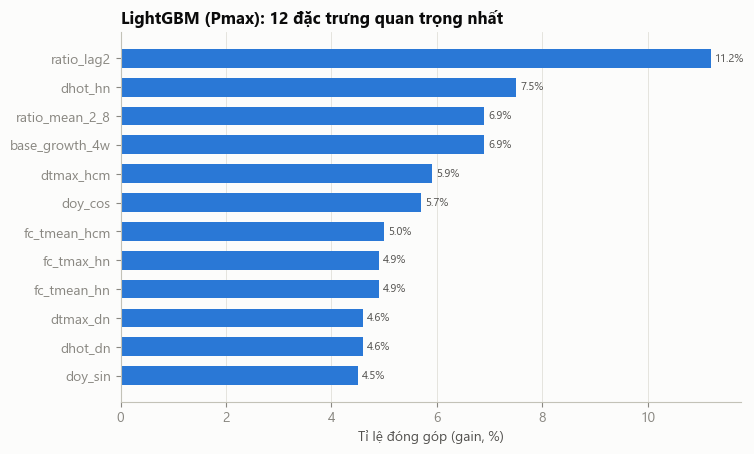

In [9]:
df = F.load()
imp, coefs = {}, {}
for t in F.TARGETS:
    X, info = F.build(t, df)
    tr = info["y"].notna() & info["base"].notna() & (X.index >= T.TRAIN_START) & (X.index <= T.TEST[1])
    gbm = T.lgb_model(**params[t]["lgb"]).fit(X[tr], info.loc[tr, "ratio"])
    imp[NAMES[t]] = pd.Series(gbm.booster_.feature_importance("gain"), index=X.columns)
    Z = F.ridge_design(X)
    rid = T.ridge_model(params[t]["ridge_alpha"]).fit(Z[tr], info.loc[tr, "ratio"])
    coefs[NAMES[t]] = pd.Series(rid[-1].coef_, index=Z.columns)
imp = pd.DataFrame(imp)
imp = (imp / imp.sum() * 100).round(1).sort_values("Pmax", ascending=False)
print("LightGBM: tỉ lệ đóng góp (gain, %):")
display(imp.head(15))

coefs = pd.DataFrame(coefs)
print("Ridge: hệ số (trên biến đã chuẩn hóa), 12 hệ số lớn nhất theo |Pmax|:")
display(coefs.reindex(coefs["Pmax"].abs().sort_values(ascending=False).index).head(12).round(4))

top = imp.head(12)["Pmax"][::-1]
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(top.index, top.values, color=C["s1"], height=0.65)
for yi, v in enumerate(top.values):
    ax.annotate(f"{v:.1f}%", (v, yi), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, color=C["ink2"])
ax.set_xlabel("Tỉ lệ đóng góp (gain, %)")
ax.set_title("LightGBM (Pmax): 12 đặc trưng quan trọng nhất")
ax.grid(axis="y", visible=False)
save(fig, "11_feature_importance")

## 6. Những ngày sai nhiều nhất (Pmax, mô hình cuối)

In [10]:
t = "pmax_mw"
d = bt[bt.target == t].dropna(subset=["y", FINAL[t]]).copy()
d["sai số %"] = (d[FINAL[t]] - d["y"]) / d["y"] * 100
cal = pd.read_csv(ROOT / "data" / "calendar.csv", parse_dates=["date"]).set_index("date")
wx = pd.read_csv(ROOT / "data" / "weather.csv", parse_dates=["date"]).set_index("date")
worst = d.reindex(d["sai số %"].abs().sort_values(ascending=False).index).head(12)
worst = worst.join(cal[["dow", "holiday_name"]]).join(wx[["fc_tmax_hn", "obs_tmax_hn", "obs_precip_hn"]])
display(worst[["y", FINAL[t], "sai số %", "dow", "holiday_name", "tet_offset", "fc_tmax_hn", "obs_tmax_hn", "obs_precip_hn"]].round(1))
print(f"Tỉ lệ ngày sai > 5%: {(d['sai số %'].abs() > 5).mean():.1%}; dự báo cao hơn thực tế ở {(d['sai số %'] > 0).mean():.1%} số ngày "
      f"(sai số trung bình có dấu: {d['sai số %'].mean():+.2f}%)")

,y,ensemble,sai số %,dow,holiday_name,tet_offset,fc_tmax_hn,obs_tmax_hn,obs_precip_hn
date,,,,,,,,,
2026-04-27,45775.0,37982.0,-17.0,0,Ngày Giỗ Tổ Hùng Vương (nghỉ bù),69,29.8,31.4,0.2
2026-04-26,40476.1,35407.2,-12.5,6,Ngày Giỗ Tổ Hùng Vương,68,29.4,29.4,3.4
2026-02-17,27919.3,31248.7,11.9,1,Tết Nguyên Đán,0,20.6,25.1,1.7
2026-05-02,40527.7,45308.4,11.8,5,NaN,74,32.2,31.7,6.5
2026-02-13,37870.2,42320.5,11.8,4,NaN,-4,25.2,25.3,0.8
2026-02-18,27942.8,31135.2,11.4,2,Mùng hai Tết Nguyên Đán,1,21.1,21.3,0.3
2026-02-21,32876.6,36613.5,11.4,5,NaN,4,28.9,28.0,0.2
2026-05-16,51653.9,47028.6,-9.0,5,NaN,88,33.0,32.8,42.8
2026-09-01,37167.0,40389.4,8.7,1,Quốc khánh,-158,34.3,34.7,0.0


Tỉ lệ ngày sai > 5%: 6.4%; dự báo cao hơn thực tế ở 39.0% số ngày (sai số trung bình có dấu: -0.41%)
